In [3]:
#)"import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.linalg import expm
from matplotlib.colors import LogNorm
from typing import List, Tuple
import numpy as np


In [5]:

def matrix_exponential_solution_u(T: float, kon_1: float, kon_2: float, koff_1: float, koff_2: float, C_eff: float, x0: np.ndarray, dt: float, duration: float, model: str = "simple"):
    x0 = x0/np.sum(x0) # normalize x0
    
    # Define the state transition matrix A
    if model == "simple":
        A = np.array([
            [-kon_1*T -kon_2*T, koff_1, koff_2, 0, 0],
            [kon_1*T, -(koff_1 + C_eff*kon_2 + kon_2*T), 0, koff_2, koff_2],
            [kon_2*T, 0, -(koff_2 + C_eff*kon_1 + kon_1*T), koff_1, koff_1],
            [0, C_eff*kon_2, C_eff*kon_1, -koff_1 -koff_2, 0],
            [0, kon_2*T, kon_1*T, 0, -koff_1 -koff_2]
        ])
    if model == "homodimer":
        A = np.array([
            [-2*kon_1*T -2*kon_2*T, koff_1, koff_2, 0, 0],
            [2*kon_1*T, -(koff_1 + C_eff*kon_2 + 2*kon_2*T), 0, koff_2, koff_2],
            [2*kon_2*T, 0, -(koff_2 + C_eff*kon_1 + 2*kon_1*T), koff_1, koff_1],
            [0, C_eff*kon_2, C_eff*kon_1, -koff_1 -koff_2, 0],
            [0, 2*kon_2*T, 2*kon_1*T, 0, -koff_1 -koff_2]
        ])
    
    # Time evolution
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    traces = np.array([expm(A*t) @ x0 for t in time])

    
    # compute equilibrium fraction of c
    if model == "simple":
        frac_c = calculate_equilibrium(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff)
        print("equilibrium fraction of state c: ", frac_c)
    if model == "homodimer":
        frac_c = calculate_equilibrium_homodimer(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff)
        print("equilibrium fraction of state c (homodimer model): ", frac_c)

    
    return x0, time, traces


def matrix_exponential_solution_f(T: float, kon_1: float, kon_2: float, koff_1: float, koff_2: float, koff_1_f: float, koff_2_f: float, x0: np.ndarray, dt: float, duration: float, model: str = "simple", beta: float = 1.0):
    x0 = x0/np.sum(x0)
    
    if model == "simple":
        # Define the state transition matrix A
        A = np.array([
            [-kon_1*T*beta -kon_2*T*beta, koff_1, koff_2, 0, 0],
            [kon_1*T*beta, -(koff_1 + kon_2*T*beta), 0, koff_2_f, koff_2],
            [kon_2*T*beta, 0, -(koff_2 + kon_1*T*beta), koff_1_f, koff_1],
            [0, 0, 0, -koff_1_f -koff_2_f, 0],
            [0, kon_2*T*beta, kon_1*T*beta, 0, -koff_1 -koff_2]
        ])
    if model == "homodimer":
        # Define the state transition matrix A
        A = np.array([
            [-2*kon_1*T*beta -2*kon_2*T*beta, koff_1, koff_2, 0, 0],
            [2*kon_1*T*beta, -(koff_1 + 2*kon_2*T*beta), 0, koff_2_f, koff_2],
            [2*kon_2*T*beta, 0, -(koff_2 + 2*kon_1*T*beta), koff_1_f, koff_1],
            [0, 0, 0, -koff_1_f -koff_2_f, 0],
            [0, 2*kon_2*T*beta, 2*kon_1*T*beta, 0, -koff_1 -koff_2]
        ])
    
    # Time evolution
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    traces = np.array([expm(A*t) @ x0 for t in time])

    
    return x0, time, traces



def plot_matrix_exponential_fits(time: np.ndarray, traces: np.ndarray): #, c_fit_tau: np.ndarray, c_fit_k: np.ndarray, fit_start: int):
    plt.rcParams['font.family'] = 'serif'         # 'sans-serif', 'serif', 'monospace', etc.
    plt.rcParams['font.serif'] = ['Times New Roman']  # or 'Georgia', 'Palatino', etc.
    plt.figure(figsize=(8, 4))
    
    plt.plot(time/60, traces[:,0], label='A', linewidth=2.5, color='#0000FF')
    plt.plot(time/60, traces[:,1], label='B1', linewidth=2.5, color='#15B01A')
    plt.plot(time/60, traces[:,2], label='B2', linewidth=2.5, color='#BBF90F')
    plt.plot(time/60, traces[:,3], label='C', linewidth=2.5, color='#E50000')
    plt.plot(time/60, traces[:,4], label='D', linewidth=2.5, color='#FFA500')


    plt.xlabel('time (min)', fontsize=16)
    plt.ylabel('state fraction', color='black', fontsize=16)
    plt.legend(loc='upper right')
    plt.grid()
    plt.legend(loc='lower right')
    plt.ylim(-0.01,1.01)
    plt.show()


def koff_under_force (xb,f):
    kb = 1.380e-23 #J/K
    T = 298.15 #K
    fb = kb*T/xb #N
    
    factor_increase = np.exp(f/fb)

    return factor_increase

# Define the exponential function for curve fitting
def first_order_model_k_timeshift(t, a, k, t0):
    return a * (1 - np.exp(-k*(t-t0)))

# Fit trace to first order model
def fit_first_order_k_timeshift(a_guess, k_guess, t0_guess, t_data, trace_data):
    p0 = [a_guess, k_guess, t0_guess]
    params, covariance = curve_fit(first_order_model_k_timeshift, t_data, trace_data, p0=p0)
    c_fit_k = first_order_model_k_timeshift(t_data, *params)
    
    ss_res = np.sum((trace_data - c_fit_k) ** 2)  # Residual sum of squares
    ss_tot = np.sum((trace_data - np.mean(trace_data)) ** 2)  # Total sum of squares
    r_squared = 1 - (ss_res / ss_tot)
    print(f"R-squared: {r_squared:.4f}")
    
    return params, covariance

# Define the exponential function for curve fitting
def first_order_model_k(t, a, b, k):
    return a * (1 - np.exp(-k*t)) + b

# Fit trace to first order model
def fit_first_order_k(a_guess, b_guess, k_guess, t_data, trace_data):
    p0 = [a_guess, b_guess, k_guess]
    params, covariance = curve_fit(first_order_model_k, t_data, trace_data, p0=p0)
    return params, covariance

# Define the exponential function for curve fitting with tau
def first_order_model_tau(t, a, b, tau):
    return a * (1 - np.exp(-t/tau)) + b

# Fit trace to first order model with tau
def fit_first_order_tau(a_guess, b_guess, tau_guess, t_data, trace_data):
    p0 = [a_guess, b_guess, tau_guess]
    params, covariance = curve_fit(first_order_model_tau, t_data, trace_data, p0=p0)
    return params, covariance

def calculate_equilibrium(T: float, kon_1: float, kon_2: float, koff_1: float, koff_2: float, C_eff: float):
    
    Kd1 = koff_1/kon_1
    Kd2 = koff_2/kon_2    
    frac_c = (T*C_eff)/(Kd1*Kd2 + Kd2*T + Kd1*T + T*T + T*C_eff)

    return frac_c


def calculate_equilibrium_homodimer(T: float, kon_1: float, kon_2: float, koff_1: float, koff_2: float, C_eff: float):
    
    Kd1 = koff_1/kon_1
    Kd2 = koff_2/kon_2    
    frac_c = (2*T*C_eff)/(Kd1*Kd2 + 2*Kd2*T + 2*Kd1*T + 4*T*T + 2*T*C_eff)

    return frac_c

def plot_koff_effective(kon: float):
    # Parameters
    k_on = kon  # fixed k_on value (1/(M*s))
    
    # Log-spaced ranges for koff and target concentration T
    koff_values = np.logspace(-6, -2, 200)    # from 1e-6 to 1e-2 (s^-1)
    Ceff_values = np.logspace(-10, -7, 200)      # from 1e-10 to 1e-7 M
    
    # Create meshgrid
    Koff, Ceff = np.meshgrid(koff_values, Ceff_values)
    
    # Calculate koff_eff
    koff_eff = 2*Koff*(Koff/(Ceff*k_on+Koff))
    
    Kd = Koff / k_on
    
    # Create figure
    fig, ax1 = plt.subplots(1, 1, figsize=(8, 6), constrained_layout=True)
    
    # Plot keq heatmap (1/s)
    pcm1 = ax1.pcolormesh(
        Ceff_values, koff_values, koff_eff.T,
        norm=LogNorm(vmin=koff_eff.min(), vmax=koff_eff.max()),
        shading='auto'
    )
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlabel('Ceff (M)')
    ax1.set_ylabel('k_off (s$^{-1}$)')
    ax1.set_title(r'$k_{off-effective}$' f' for kon = {k_on:.2e}')
    cbar1 = fig.colorbar(pcm1, ax=ax1, label=r'$k_{off_effective}$ [log scale]')
    
    # Add secondary y-axis for Kd to ax1
    secax1 = ax1.secondary_yaxis(
        'right', 
        functions=(lambda koff: koff / k_on, lambda kd: kd * k_on)
    )
    secax1.set_yscale('log')
    secax1.set_ylabel(r'$K_d = k_{\mathrm{off}}/k_{\mathrm{on}}$ (M)')
    
    
    Ceff_levels = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
    CS1 = ax1.contour(
            Ceff_values, koff_values, koff_eff.T,
            levels=Ceff_levels, colors='red', linewidths=1
        )
    ax1.clabel(CS1, inline=True, fmt=lambda v: f"{v} 1/s", fontsize=12)
    
    
    plt.show()


def matrix_exponential_solution_multiple_steps(
    T_list: List[float],
    C_eff: float,
    kon_1: float, kon_2: float,
    koff_1: float, koff_2: float,
    koff_1_f: float, koff_2_f: float,
    x0: np.ndarray,
    dt: float,
    duration_list: List[float],
    mode_list: List[int],
    model: str = "simple",
    beta: float = 1.0,
) -> Tuple[np.ndarray, np.ndarray]:

    if not (len(T_list) == len(duration_list) == len(mode_list)):
        raise ValueError("Target, Duration, and Mode lists lengths do not match")

    times_segs = []
    traces_segs = []
    t_offset = 0.0

    for i, (T, duration, mode) in enumerate(zip(T_list, duration_list, mode_list), start=1):
        print(f"profile step {i}")

        if mode == 0:
            # association/unforced segment
            _, time, traces = matrix_exponential_solution_u(
                T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2,
                C_eff=C_eff, x0=x0, dt=dt, duration=duration*60, model=model
            )
        elif mode == 1:
            # forced dissociation segment
            _, time, traces = matrix_exponential_solution_f(
                T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2,
                koff_1_f=koff_1_f, koff_2_f=koff_2_f,
                x0=x0, dt=dt, duration=duration*60, model=model, beta=beta
            )
        else:
            raise ValueError(f"Unsupported mode {mode}; expected 0 or 1")

        # Ensure 1D time and 2D traces
        time = np.asarray(time).reshape(-1)
        traces = np.atleast_2d(np.asarray(traces))

        # Offset local time to make a continuous global time
        times_segs.append(time + t_offset)
        traces_segs.append(traces)

        # Prepare for next step
        t_offset += time[-1]  # last absolute time
        x0 = traces[-1, :]

    # Concatenate all segments
    times = np.concatenate(times_segs, axis=0)
    traces_total = np.vstack(traces_segs)
    return times, traces_total


def plot_matrix_exponential_multiple_steps(time: np.ndarray, traces: np.ndarray, dt: float, T_list: List, duration_list: List, mode_list: List):
    plt.rcParams['font.family'] = 'serif'         # 'sans-serif', 'serif', 'monospace', etc.
    plt.rcParams['font.serif'] = ['Times New Roman']  # or 'Georgia', 'Palatino', etc.
    plt.figure(figsize=(8, 4))
    
    target_profile = np.asarray([])
    mode_profile = np.asarray([])

    for i, T in enumerate(T_list):
        mode = mode_list[i]
        duration = duration_list[i]
        
        num_timepoints = int(round(60*duration/dt))
        
        targets = np.ones(num_timepoints)*T
        modes = np.ones(num_timepoints)*mode
        
        target_profile = np.concatenate([target_profile, targets],axis=0)
        mode_profile = np.concatenate([mode_profile, modes], axis=0)
        
    
    plt.plot(time/60, traces[:,0], label='A', linewidth=2.5, color='#0000FF')
    plt.plot(time/60, traces[:,1], label='B1', linewidth=2.5, color='#15B01A')
    plt.plot(time/60, traces[:,2], label='B2', linewidth=2.5, color='#BBF90F')
    plt.plot(time/60, traces[:,3], label='C', linewidth=2.5, color='#E50000')
    plt.plot(time/60, traces[:,4], label='D', linewidth=2.5, color='#FFA500')
    
    plt.fill_between(time/60, -0.05, 1.05, where=mode_profile == 1, color='blue', alpha=0.2, label='forced mode')
    
    plt.xlabel('time (min)', fontsize=16)
    plt.ylabel('state fraction', color='black', fontsize=16)
    plt.legend(loc='upper right')
    plt.grid()
    plt.legend(loc='lower right')
    plt.ylim(-0.01,1.01)
    
    ax2 = plt.gca().twinx()
    ax2.semilogy(time/60, target_profile, label='target', color='black')
    
    plt.show()

def calculate_k_eff_u(kon: float, koff: float, C_eff: float, T: float):
    koff_tilda = 2*koff*(koff/(C_eff*kon+koff))
    kon_tilda = 2*kon
    keff_u = kon_tilda*T + koff_tilda
    return kon_tilda, koff_tilda, keff_u

def calculate_kon_eff_full(kon: float, koff: float, C_eff: float, T: float, model: str = "simple"):
    if model == "simple":
        return 2*kon * (kon*C_eff) / (koff + kon*(C_eff+T))
    if model == "homodimer":
        return 2*2*kon * (kon*C_eff) / (koff + kon*(C_eff+2*T))
    else:
        return

def calculate_koff_eff_full(kon: float, koff: float, C_eff: float, T: float, model: str = "simple"):
    if model == "simple":
        return 2*koff * (koff) / (koff + kon*(C_eff+T))
    if model == "homodimer":
        return 2*koff * (koff) / (koff + kon*(C_eff+2*T))
    else:
        return

def calculate_k_eff_full(kon: float, koff: float, C_eff: float, T: float, model: str = "simple"):
    kon_eff = calculate_kon_eff_full(kon, koff, C_eff, T, model=model)
    koff_eff = calculate_koff_eff_full(kon, koff, C_eff, T, model=model)
    k_eff = kon_eff*T + koff_eff
    return k_eff


In [9]:
## LDS Figure Plots ###
timestep = 0.5

kon_1 = 1.2e7 # 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.74e-3 #1.5e-3  # 1.74e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 5e-9 # M
koff_1_f = 5*koff_1 #* koff_under_force(xb1, Fmag)
koff_2_f = 5*koff_2 #* koff_under_force(xb1, Fmag)

equilibrium fraction of state c:  0.09021028492206305


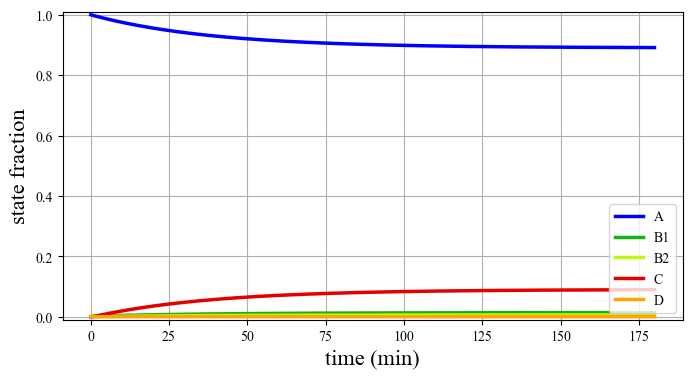

equilibrium fraction of state c (homodimer model):  0.1625487646293888


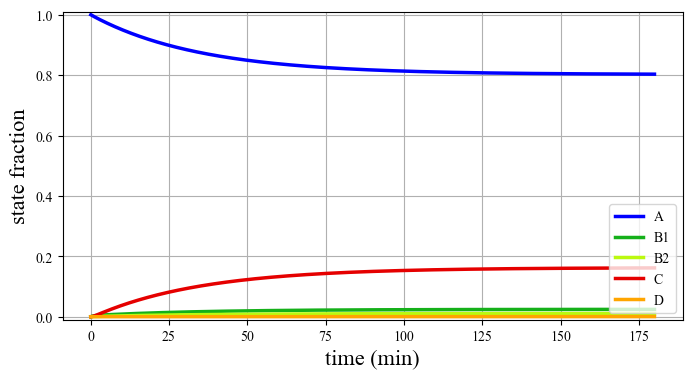

In [12]:
timestep = 0.5
kon_1 = 3.8e5
kon_2 = 1.4e5
koff_1 = 2.5e-3
koff_2 = 2.1e-3
C_eff = 100e-9

T=100e-12
x0 = [1, 0, 0, 0, 0 ]

x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 3*60*60, model="simple")

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 3*60*60, model="homodimer")

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)


In [17]:
# set parameters for constant target simulations
timestep = 0.5 #s Note: the stochastic simulations can break down if timestep is too large. Can very by comparing to LDS with constant T
# Fmag = 0e-12 #pN
# xb1 = 5e-10 #m
# xb2 = 5e-10 #m

kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.74e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 10e-9 # M
koff_1_f = 5*koff_1 #* koff_under_force(xb1, Fmag)
koff_2_f = 5*koff_2 #* koff_under_force(xb1, Fmag)
Fmag = 0e-12 #pN
model = "simple"
# xb1 = 5e-10 #m
# xb2 = 5e-10 #m
# print("dissociation factor increase for state c: ", koff_under_force(xb1, Fmag))
print("Kd: ", koff_1/kon_1)

Kd:  1.45e-10


equilibrium fraction of state c:  0.3193255843658194


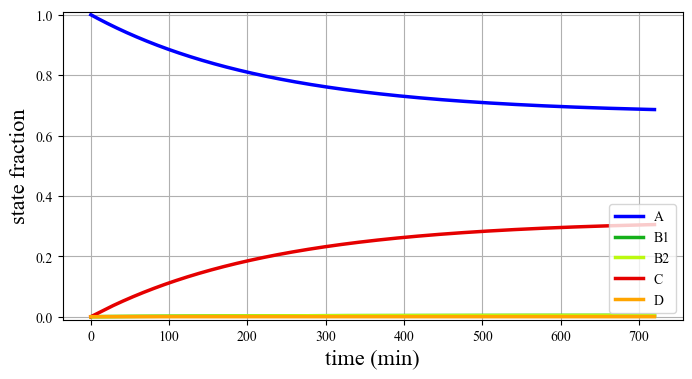

equilibrium fraction of state c:  0.3193255843658194


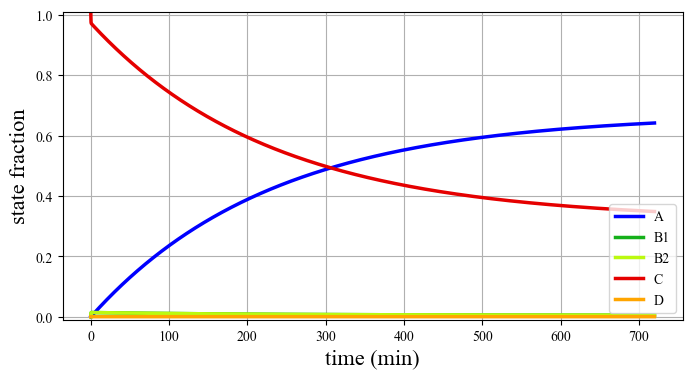

equilibrium fraction of state c:  0.5929962693122208


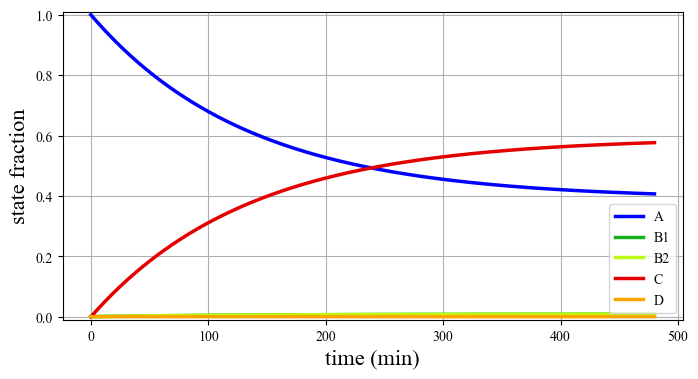

equilibrium fraction of state c:  0.5929962693122208


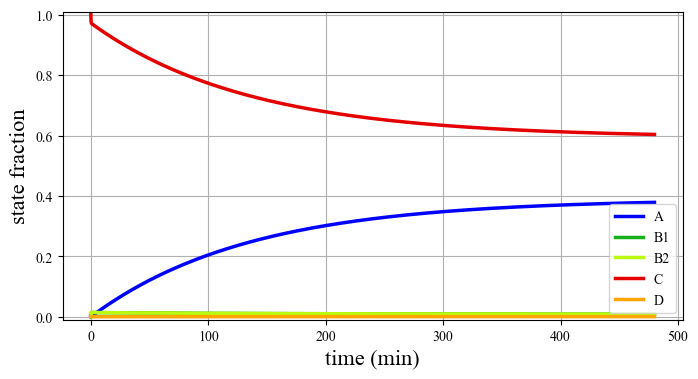

equilibrium fraction of state c:  0.8062890546260835


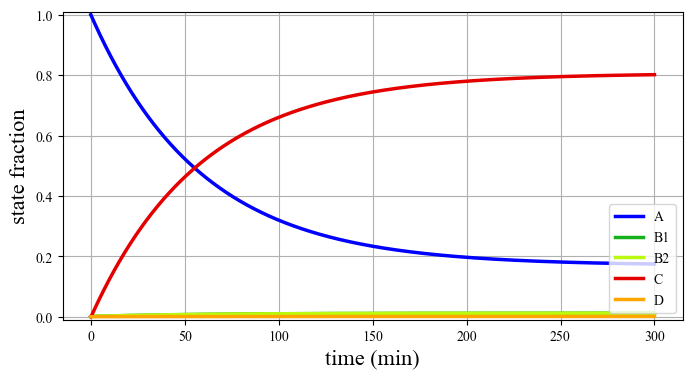

equilibrium fraction of state c:  0.8062890546260835


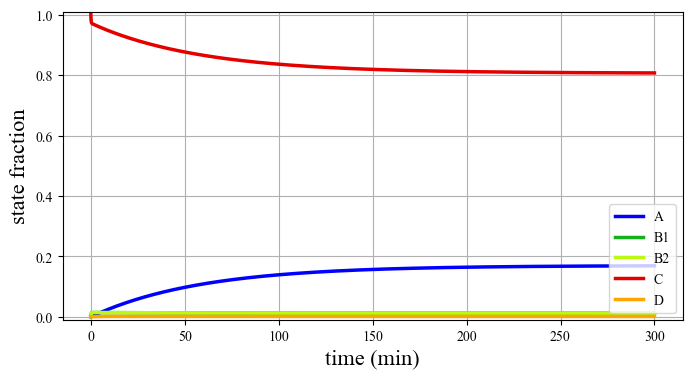

In [23]:
T=1e-12
x0 = [1, 0, 0, 0, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 12*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

x0 = [0, 0, 0, 1, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 12*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)


T=3.2e-12
x0 = [1, 0, 0, 0, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 8*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

x0 = [0, 0, 0, 1, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 8*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)



T=10e-12
x0 = [1, 0, 0, 0, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 5*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

x0 = [0, 0, 0, 1, 0 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 5*60*60, model=model)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

# T=1e-12
# x0 = [1, 0, 0, 0, 0 ]
# x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 5*60*60, model=model)
#
# plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)


In [93]:
timestep = 0.5 #s Note: the stochastic simulations can break down if timestep is too large. Can very by comparing to LDS with constant T
kon_1 = 1.2e7 # 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 0.3*1.24e-3 #1.5e-3  # 1.74e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 5e-9 # M
koff_1_f = 3*koff_1 #* koff_under_force(xb1, Fmag)
koff_2_f = 3*koff_2 #* koff_under_force(xb1, Fmag)
model = "homodimer"
beta = 1

n_samples_per_window = 20
n_steps_per_window = n_samples_per_window*2 + 2
n_windows = 2

T_list = np.concatenate([
    (10e-12) * np.ones(43),
    0.0 * np.ones(41),
])
duration_list =  n_windows*([2.5, 2.5]+  n_samples_per_window*[0.65, 4.35])
mode_list = n_steps_per_window*[1,0]
mode_list_alt = n_steps_per_window*[0,0]
x0 = [1,0,0,0,0]

print(len(T_list), len(duration_list), len(mode_list))

84 84 84


profile step 1
profile step 2
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 3
profile step 4
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 5
profile step 6
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 7
profile step 8
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 9
profile step 10
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 11
profile step 12
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 13
profile step 14
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 15
profile step 16
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 17
profile step 18
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 19
profile step 20
equilibrium fraction of state c (homodimer model):

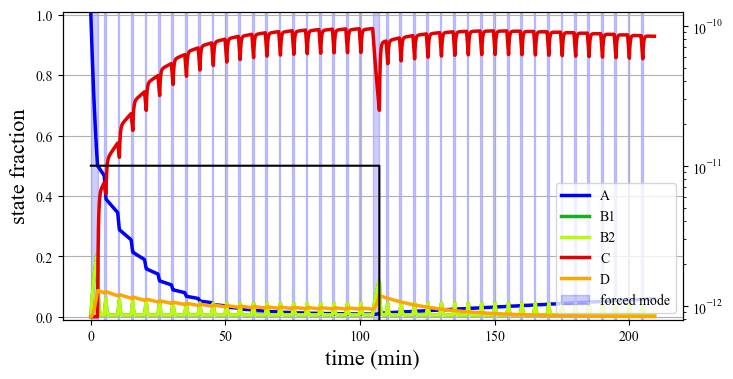

In [94]:

# times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list, model=model, beta=1)
#
# plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list)

times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list, model=model, beta=10)

plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list)


# times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list_alt, model=model,beta=beta)
#
# plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list_alt)


In [95]:
timestep = 0.5 #s Note: the stochastic simulations can break down if timestep is too large. Can very by comparing to LDS with constant T
kon_1 = 1.2e7 # 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 0.3*1.24e-3 #1.5e-3  # 1.74e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 5e-9 # M
koff_1_f = 3*koff_1 #* koff_under_force(xb1, Fmag)
koff_2_f = 3*koff_2 #* koff_under_force(xb1, Fmag)
model = "homodimer"
beta = 1

n_samples_per_window = 20
n_steps_per_window = n_samples_per_window*2 + 10
n_windows = 2

T_list = np.concatenate([
    (10e-12) * np.ones(50),
    0.0 * np.ones(50),
])
duration_list =  n_windows*(5*[0.5, 0.5]+  n_samples_per_window*[0.65, 4.35])
mode_list = n_steps_per_window*[1,0]
mode_list_alt = n_steps_per_window*[0,0]
x0 = [1,0,0,0,0]

print(len(T_list), len(duration_list), len(mode_list))

100 100 100


profile step 1
profile step 2
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 3
profile step 4
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 5
profile step 6
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 7
profile step 8
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 9
profile step 10
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 11
profile step 12
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 13
profile step 14
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 15
profile step 16
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 17
profile step 18
equilibrium fraction of state c (homodimer model):  0.9746493698891824
profile step 19
profile step 20
equilibrium fraction of state c (homodimer model):

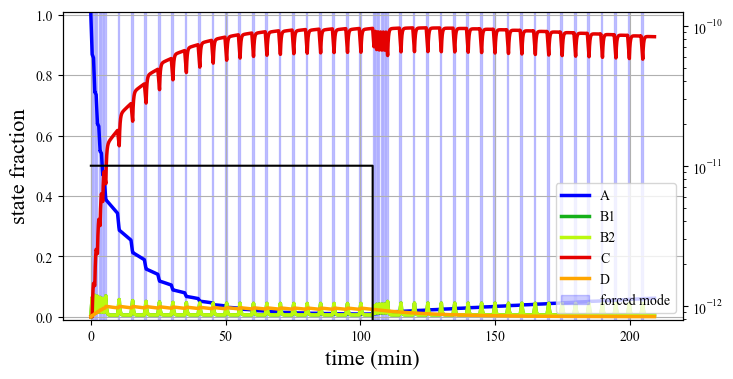

In [96]:

# times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list, model=model, beta=1)
#
# plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list)

times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list, model=model, beta=10)

plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list)
#
#
# times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list_alt, model=model,beta=beta)
#
# plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list_alt)


profile step 1
profile step 2
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 3
profile step 4
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 5
profile step 6
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 7
profile step 8
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 9
profile step 10
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 11
profile step 12
equilibrium fraction of state c (homodimer model):  0.8679718391358857
profile step 13
profile step 14
equilibrium fraction of state c (homodimer model):  0.8679718391358857
profile step 15
profile step 16
equilibrium fraction of state c (homodimer model):  0.8679718391358857
profile step 17
profile step 18
equilibrium fraction of state c (homodimer model):  0.8679718391358857
profile step 19
profile step 20
equilibrium fraction of state c (homodimer model):  0.8

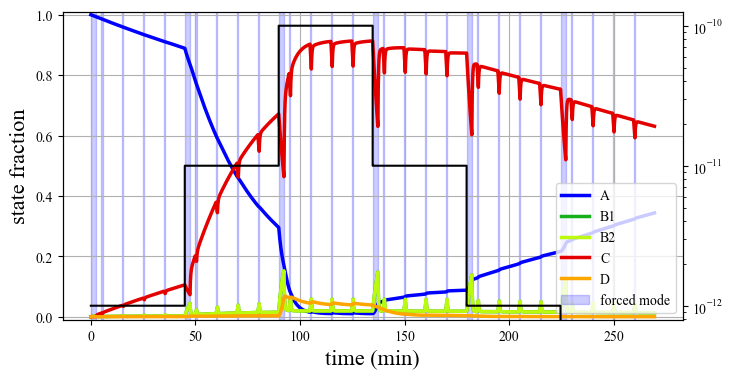

profile step 1
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 2
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 3
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 4
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 5
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 6
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 7
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 8
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 9
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 10
equilibrium fraction of state c (homodimer model):  0.474043485589078
profile step 11
equilibrium fraction of state c (homodimer model):  0.8679718391358857
profile step 12
equilibrium fraction of state c (homodimer mod

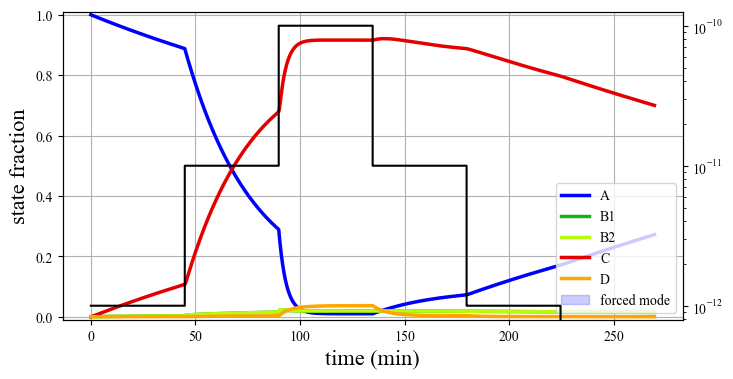

In [48]:
timestep = 0.5 #s Note: the stochastic simulations can break down if timestep is too large. Can very by comparing to LDS with constant T
kon_1 = 1.2e7 # 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.24e-3 #1.5e-3  # 1.74e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 5e-9 # M
koff_1_f = 1*koff_1 #* koff_under_force(xb1, Fmag)
koff_2_f = 1*koff_2 #* koff_under_force(xb1, Fmag)
model = "homodimer"

T_list = np.concatenate((1e-12*np.ones(10), 10e-12*np.ones(10), 100e-12*np.ones(10), 10e-12*np.ones(10), 1e-12*np.ones(10), 0.0e-12*np.ones(10)))
duration_list =  6*([2.5, 2.5]+  4*[0.65, 9.35])
mode_list = 6*5*[1,0]
mode_list_alt = 6*5*[0,0]
x0 = [1,0,0,0,0]

times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list, model=model)

plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list)

times, traces = matrix_exponential_solution_multiple_steps(T_list=T_list, C_eff=C_eff,kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, koff_1_f=koff_1_f, koff_2_f=koff_2_f, x0=x0, dt=timestep, duration_list=duration_list, mode_list=mode_list_alt, model=model)

plot_matrix_exponential_multiple_steps(time=times, traces=traces, dt=timestep, T_list=T_list, duration_list=duration_list, mode_list=mode_list_alt)


equilibrium fraction of state c:  0.0


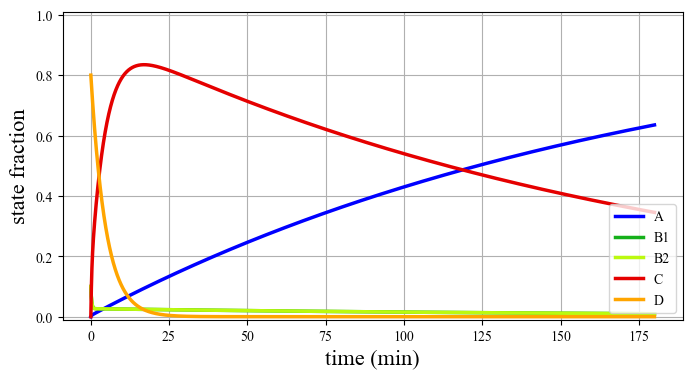

In [7]:
T=0
x0 = [0, 0.1, 0.1, 0.0, 0.8 ]
x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 3*60*60)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)



equilibrium fraction of state c (homodimer model):  0.5826449019663537


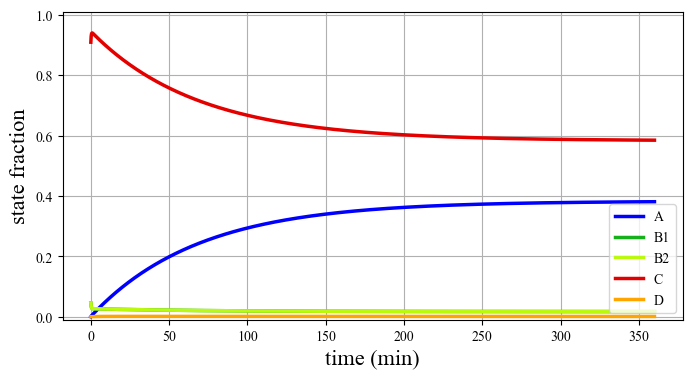

In [8]:
T=3.2e-12
x0 = [0.0, 0.05, 0.05, 1.0, 0 ]

x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 360*60*1, model="homodimer")

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)

# print("k from tau fit: ", 1/tau_fit_tau)
# print(x0)
# kon_tilda, koff_tilda, keff = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff=C_eff, T=10e-12)
# print(kon_tilda, koff_tilda, keff)

In [31]:
traces.shape

(43200, 5)

In [13]:
T_list = [0, 1e-12, 1e-11, 1e-10, 1e-9]

for T in T_list:
    kon_tilda, koff_tilda, keff_u = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff = 20e-9, T = T)
    print("T: ", T, "keff: ", keff_u, "kon_eff: ", kon_tilda, "koff_eff: ", koff_tilda)
    print("tau (min): ", (1/keff_u)/60)

T:  0 keff:  9.25150421179302e-05 kon_eff:  3200000.0 koff_eff:  9.25150421179302e-05
tau (min):  180.15088449531737
T:  1e-12 keff:  9.57150421179302e-05 kon_eff:  3200000.0 koff_eff:  9.25150421179302e-05
tau (min):  174.12797714837464
T:  1e-11 keff:  0.0001245150421179302 kon_eff:  3200000.0 koff_eff:  9.25150421179302e-05
tau (min):  133.85263646203805
T:  1e-10 keff:  0.00041251504211793025 kon_eff:  3200000.0 koff_eff:  9.25150421179302e-05
tau (min):  40.40256709451575
T:  1e-09 keff:  0.0032925150421179304 kon_eff:  3200000.0 koff_eff:  9.25150421179302e-05
tau (min):  5.061986491623051


equilibrium fraction of state c:  0.0
r**2 of fit:  6.253065971795202e-06


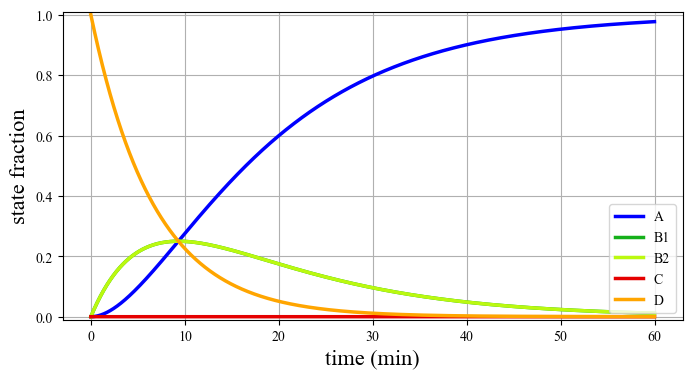

k from tau fit:  1.939260269320102e-05
[0. 0. 0. 0. 1.]
0.0010828169014084506


In [23]:
T=0
kon_1 = 1.6e6 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.24e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 1e-9 # M
koff_1_f = koff_1 * koff_under_force(xb1, Fmag)
koff_2_f = koff_2 * koff_under_force(xb1, Fmag)

x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=0, x0=[0, 0, 0, 0, 1], dt=timestep, duration= 60*60*1)

plot_matrix_exponential_fits(time=time, traces=traces) #, c_fit_tau=c_fit_tau, c_fit_k=c_fit_k, fit_start=5*60)
print(x0)
kon_tilda, koff_tilda, keff = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-9)
print(kon_tilda*T+koff_tilda)

[Target]:  1e-12
equilibrium fraction of state c (homodimer model):  0.06493272248475884
R-squared: 0.9992


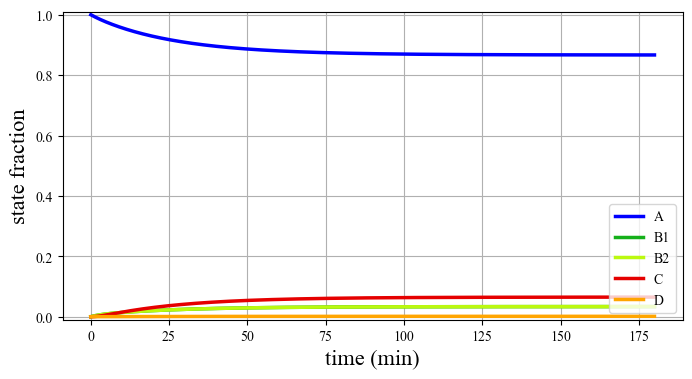

predicted equilibrium value of state C (a_fit):  0.06513086341081577
keff_fit:  0.0006011279900160829
tau_fit (minutes):  27.725654009590798
[Target]:  3.2e-12
equilibrium fraction of state c (homodimer model):  0.15953186261204622
R-squared: 0.9988


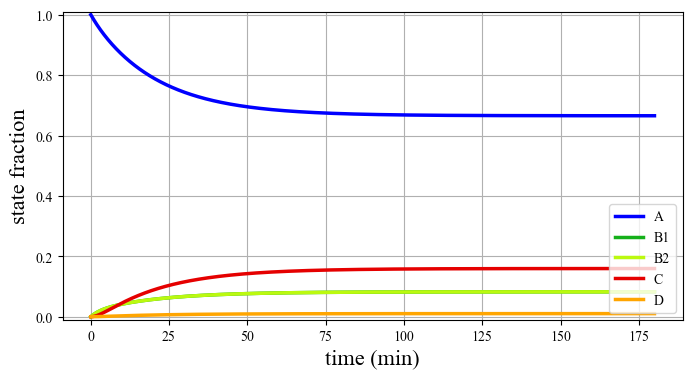

predicted equilibrium value of state C (a_fit):  0.15996627306365158
keff_fit:  0.0007526262562136708
tau_fit (minutes):  22.144678755314374
[Target]:  1e-11
equilibrium fraction of state c (homodimer model):  0.2802646944336318
R-squared: 0.9976


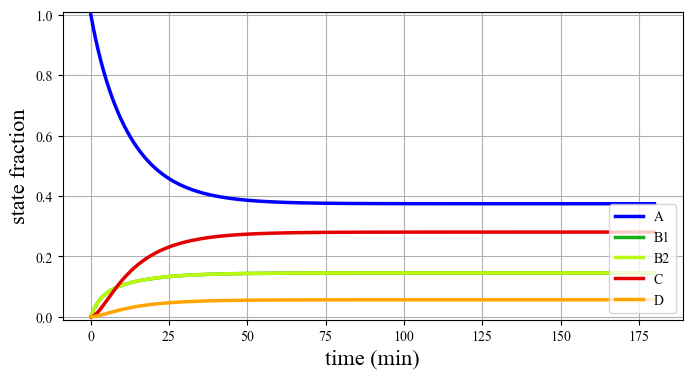

predicted equilibrium value of state C (a_fit):  0.2809151087361515
keff_fit:  0.0011858905519706055
tau_fit (minutes):  14.054135635848949
[Target]:  3.2e-11
equilibrium fraction of state c (homodimer model):  0.3235791448746973
R-squared: 0.9949


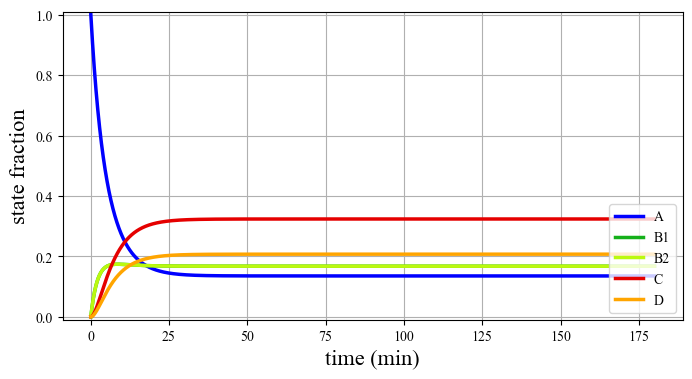

predicted equilibrium value of state C (a_fit):  0.32414108760644256
keff_fit:  0.002355579305089315
tau_fit (minutes):  7.075400361455768
[Target]:  1e-10
equilibrium fraction of state c (homodimer model):  0.23999200026665776
R-squared: 0.9930


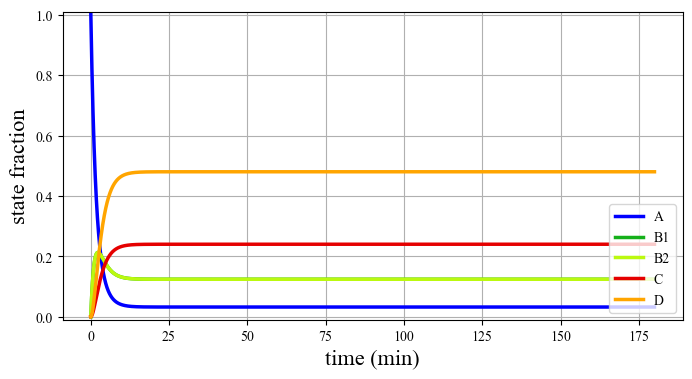

predicted equilibrium value of state C (a_fit):  0.24021260645949996
keff_fit:  0.0052251547495725855
tau_fit (minutes):  3.1896981937290927


In [202]:
kon_1 = 2*1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.24e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 0.1e-9 # M
model = "homodimer"

Ts = [1e-12, 3.2e-12, 10e-12, 32e-12, 100e-12]
x0 = [1, 0, 0, 0, 0]
k_fits = []

for T in Ts:
    print("[Target]: ", T)
    x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 3*60*60, model=model)
    c_t = traces[:, 3]
    a_t = traces[:, 0]
    
    # Fit with first order kinetics
    kon_eff_guess, koff_eff_guess, keff_guess = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff=C_eff, T=T)
    
    a_guess = np.max(c_t)
    k_guess = keff_guess
    # b_guess = 0.00
    t0_guess = 0.00
    params, _ = fit_first_order_k_timeshift(a_guess, k_guess, t0_guess, time, c_t)
    a_fit, k_fit, t0_fit = params
    k_fits.append(k_fit)
    plot_matrix_exponential_fits(time=time, traces=traces)
    print("predicted equilibrium value of state C (a_fit): ", a_fit)
    print("keff_fit: ", k_fit)
    print("tau_fit (minutes): ", (1/k_fit)/60)




[Target]:  0.0
equilibrium fraction of state c:  0.0
R-squared: 0.0000


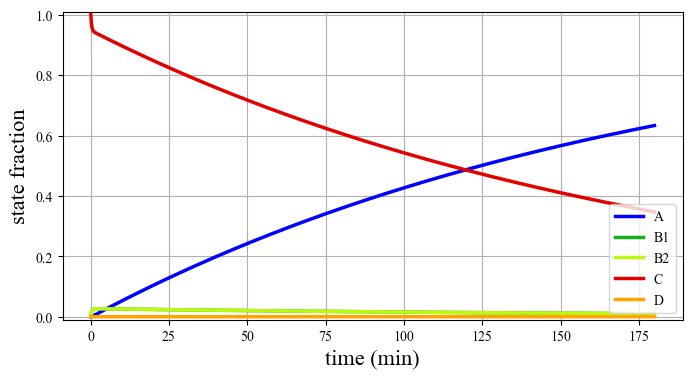

predicted equilibrium value of state C (a_fit):  0.41774619193143947
keff_fit:  0.001300995078954892
tau_fit (minutes):  12.810706924468338
[Target]:  1e-12
equilibrium fraction of state c:  0.18999848001215994
R-squared: 0.0000


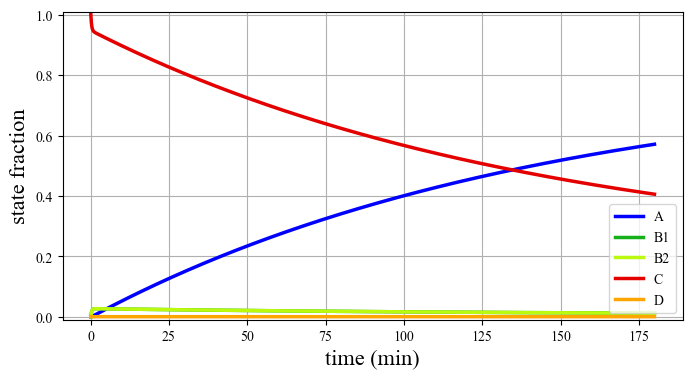

predicted equilibrium value of state C (a_fit):  0.3933973474471554
keff_fit:  0.0012623046367740826
tau_fit (minutes):  13.203363262024947
[Target]:  3.2e-12
equilibrium fraction of state c:  0.4214603390016238
R-squared: -0.0000


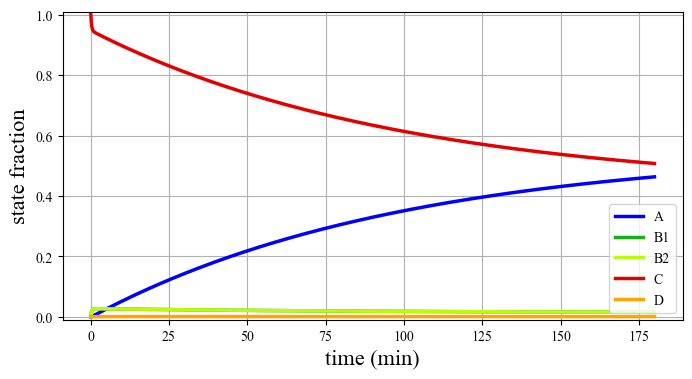

predicted equilibrium value of state C (a_fit):  0.348399759698348
keff_fit:  0.0011982569796507752
tau_fit (minutes):  13.90909208100258
[Target]:  1e-11
equilibrium fraction of state c:  0.6754474839581223
R-squared: 0.0000


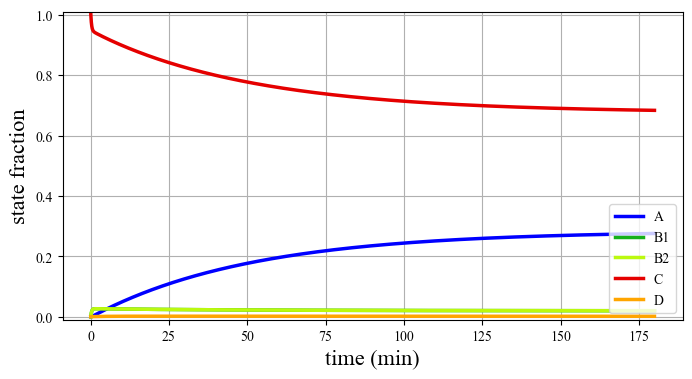

predicted equilibrium value of state C (a_fit):  0.25858286239193795
keff_fit:  0.0017298701961480862
tau_fit (minutes):  9.634634265494862
[Target]:  3.2e-11
equilibrium fraction of state c:  0.8362558733908607
R-squared: 0.0000


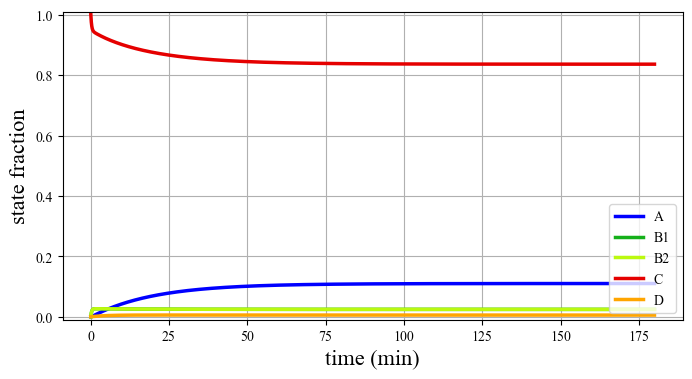

predicted equilibrium value of state C (a_fit):  0.1556762702358646
keff_fit:  0.004481700464103545
tau_fit (minutes):  3.7188265481281846
[Target]:  1e-10
equilibrium fraction of state c:  0.8928172849426365
R-squared: -0.0000


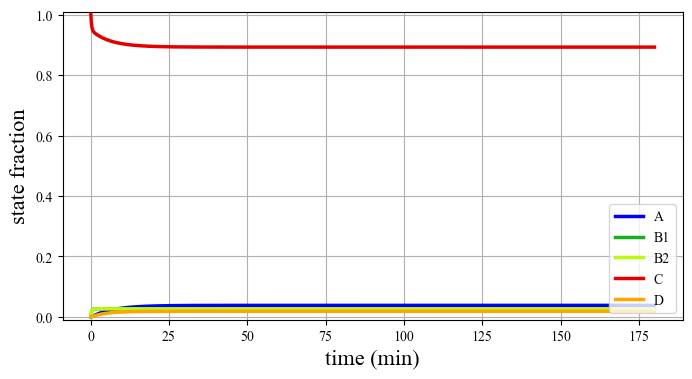

predicted equilibrium value of state C (a_fit):  0.10664082751618609
keff_fit:  0.008349004385005493
tau_fit (minutes):  1.9962460070807235


In [16]:
kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.74e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 5e-9 # M
model = "simple"

Ts = [0.0e-12, 1e-12, 3.2e-12, 10e-12, 32e-12, 100e-12]
x0 = [0, 0, 0, 1, 0]
k_fits = []

for T in Ts:
    print("[Target]: ", T)
    x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=C_eff, x0=x0, dt=timestep, duration= 3*60*60, model=model)
    c_t = traces[:, 3]
    a_t = traces[:, 0]
    
    # Fit with first order kinetics
    kon_eff_guess, koff_eff_guess, keff_guess = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff=C_eff, T=T)
    
    a_guess = np.max(c_t)
    k_guess = keff_guess
    # b_guess = 0.00
    t0_guess = 0.00
    params, _ = fit_first_order_k_timeshift(a_guess, k_guess, t0_guess, time[1000:], c_t[1000:])
    a_fit, k_fit, t0_fit = params
    k_fits.append(k_fit)
    plot_matrix_exponential_fits(time=time, traces=traces)
    print("predicted equilibrium value of state C (a_fit): ", 1-a_fit)
    print("keff_fit: ", k_fit)
    print("tau_fit (minutes): ", (1/k_fit)/60)




[C_effective]:  1e-10
equilibrium fraction of state c (homodimer model):  0.009170525929662068
R-squared: 0.9975


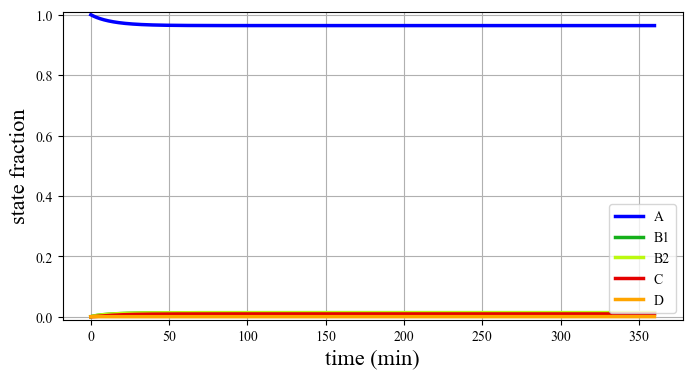

predicted equilibrium value of state C (a_fit):  0.009181243480210504
keff_fit:  0.0010611755913233285
tau_fit (minutes):  15.70585189005588
[C_effective]:  3.2e-10
equilibrium fraction of state c (homodimer model):  0.028765337767989577
R-squared: 0.9996


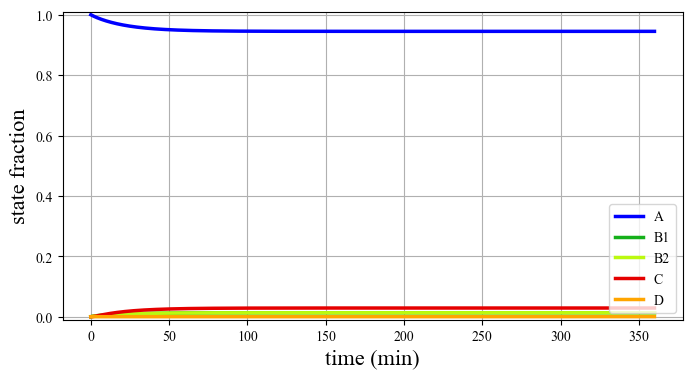

predicted equilibrium value of state C (a_fit):  0.028779826930215073
keff_fit:  0.0007452842580709327
tau_fit (minutes):  22.36283201500334
[C_effective]:  1e-09
equilibrium fraction of state c (homodimer model):  0.084713456732602
R-squared: 1.0000


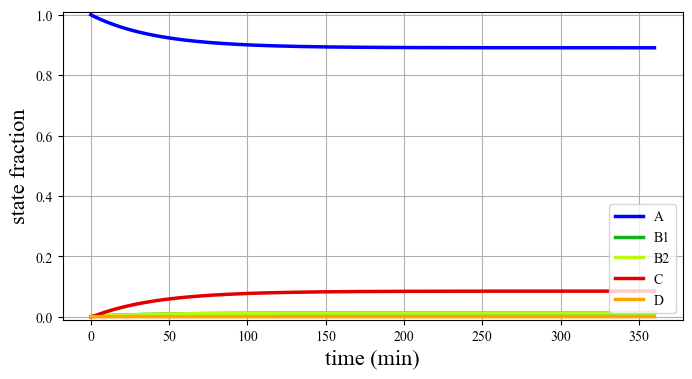

predicted equilibrium value of state C (a_fit):  0.08472295118895702
keff_fit:  0.00040155384974369974
tau_fit (minutes):  41.50543364807614
[C_effective]:  3.2e-09
equilibrium fraction of state c (homodimer model):  0.22849798279124572
R-squared: 1.0000


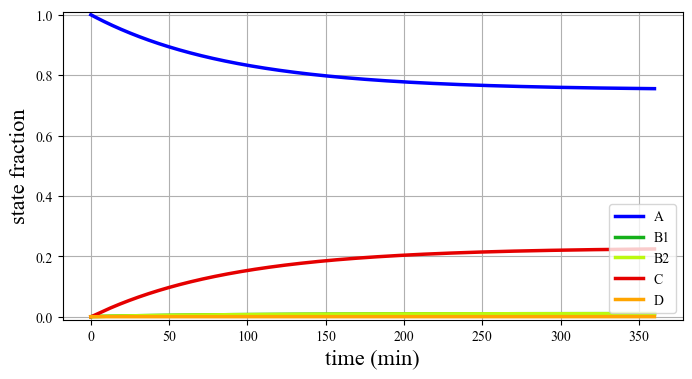

predicted equilibrium value of state C (a_fit):  0.22850280358014205
keff_fit:  0.00018538375936747128
tau_fit (minutes):  89.90359632113014
[C_effective]:  1e-08
equilibrium fraction of state c (homodimer model):  0.4806652406931193
R-squared: 1.0000


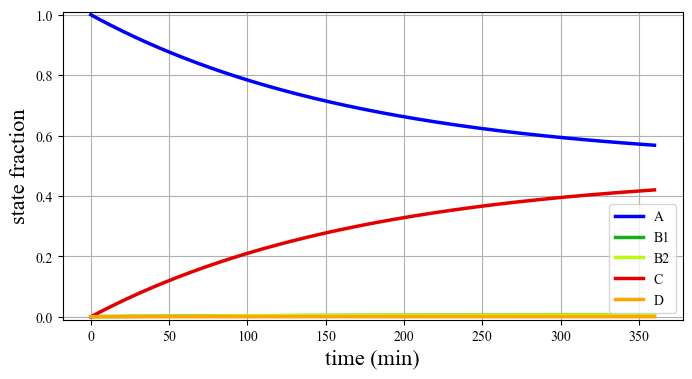

predicted equilibrium value of state C (a_fit):  0.48066732471175355
keff_fit:  9.571556951213961e-05
tau_fit (minutes):  174.1270177006347
[C_effective]:  3.2e-08
equilibrium fraction of state c (homodimer model):  0.7475849501804718
R-squared: 1.0000


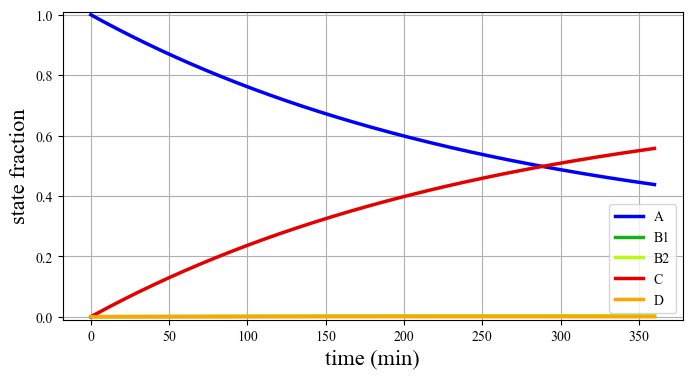

predicted equilibrium value of state C (a_fit):  0.7475854739057393
keff_fit:  6.334414099963036e-05
tau_fit (minutes):  263.1129951981498
[C_effective]:  1e-07
equilibrium fraction of state c (homodimer model):  0.9024904223203932
R-squared: 1.0000


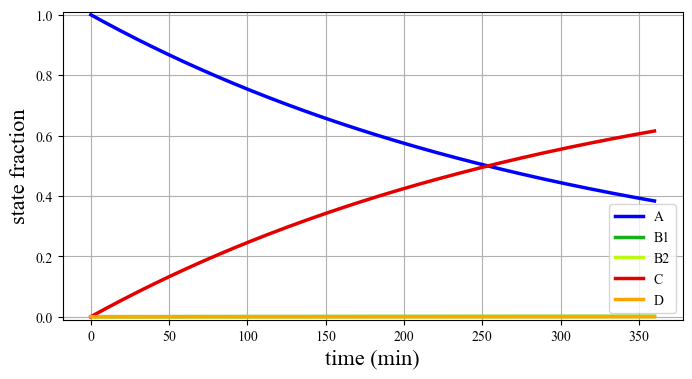

predicted equilibrium value of state C (a_fit):  0.9024905170459034
keff_fit:  5.295495483685219e-05
tau_fit (minutes):  314.73290304967026


In [19]:
kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.74e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
model = "homodimer"
T = 1e-12
x0 = [1, 0, 0, 0, 0]
Ceffs = [100e-12, 320e-12,1e-9, 3.2e-9, 10e-9, 32e-9, 100e-9]
k_fits = []

for Ceff in Ceffs:
    print("[C_effective]: ", Ceff)
    x0, time, traces = matrix_exponential_solution_u(T=T, kon_1=kon_1, kon_2=kon_2, koff_1=koff_1, koff_2=koff_2, C_eff=Ceff, x0=x0, dt=timestep, duration= 6*60*60, model=model)
    c_t = traces[:, 3]
    a_t = traces[:, 0]

    # Fit with first order kinetics
    kon_eff_guess, koff_eff_guess, keff_guess = calculate_k_eff_u(kon=kon_1, koff=koff_1, C_eff=C_eff, T=T)

    a_guess = np.max(c_t)
    k_guess = keff_guess
    # b_guess = 0.00
    t0_guess = 0.00
    params, _ = fit_first_order_k_timeshift(a_guess, k_guess, t0_guess, time, c_t)
    a_fit, k_fit, t0_fit = params
    k_fits.append(k_fit)
    plot_matrix_exponential_fits(time=time, traces=traces)
    print("predicted equilibrium value of state C (a_fit): ", a_fit)
    print("keff_fit: ", k_fit)
    print("tau_fit (minutes): ", (1/k_fit)/60)




Fitted line: y = 23656679.844710x + 0.000048
fitted kon = 23656679.844710
fitted koff = 0.000048
R-squared: 1.0000
R-squared approx: 0.9999


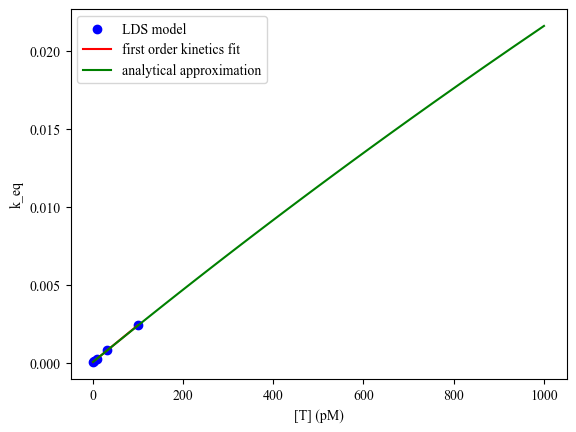

In [31]:
#Verify first order kinetics via linearity wrt [T]

# Data
x = np.array(Ts)  # Independent variable
x_plot = np.logspace(-12,-9,100)
y = np.array(k_fits) # Dependent variable

# Fit linear model: y = mx + b
coefficients = np.polyfit(x, y, 1)  # Degree 1 for a linear fit
m, b = coefficients
print(f"Fitted line: y = {m:.6f}x + {b:.6f}")
print(f"fitted kon = {m:.6f}")
print(f"fitted koff = {b:.6f}")


# Generate fitted line values
y_fit = m * x + b

# Compute R^2
ss_res = np.sum((y - y_fit) ** 2)  # Residual sum of squares
ss_tot = np.sum((y - np.mean(y)) ** 2)  # Total sum of squares
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.4f}")

# Generate approximated data for keq

y_approx = calculate_k_eff_full(kon=kon_1, koff=koff_2, C_eff=C_eff, T=x, model=model)
y_approx_plot = calculate_k_eff_full(kon=kon_1, koff=koff_2, C_eff=C_eff, T=x_plot, model=model)


# # Compute R^2
ss_res_approx = np.sum((y - y_approx) ** 2)  # Residual sum of squares
ss_tot_approx = np.sum((y - np.mean(y)) ** 2)  # Total sum of squares
r_squared_approx = 1 - (ss_res_approx / ss_tot_approx)
print(f"R-squared approx: {r_squared_approx:.4f}")


# Plot the data
plt.scatter(1e12*x, y, color='blue', label='LDS model')  # Scatter plot for data points
plt.plot(1e12*x, y_fit, color='red', label="first order kinetics fit")#label=f'Fit: y = {m:.3e}x + {b:.3e}')  # Fitted line
plt.plot(1e12*x_plot, y_approx_plot, color='green', label=f'analytical approximation')  # Approximation

plt.xlabel("[T] (pM)")
plt.ylabel("k_eq")
#plt.title("Linear Fit to Data")
plt.legend()
plt.show()


In [162]:
np.logspace(-12,-9,7)

array([1.00000000e-12, 3.16227766e-12, 1.00000000e-11, 3.16227766e-11,
       1.00000000e-10, 3.16227766e-10, 1.00000000e-09])

In [14]:
# Comparison of fit values with analytical approximation values
print(m)
print(2*kon_1)
print(b)
print(2*koff_1*(koff_1/(C_eff*kon_1+koff_1)))

557834.7187304508
600000.0
0.000209249154198324
0.00014285714285714284


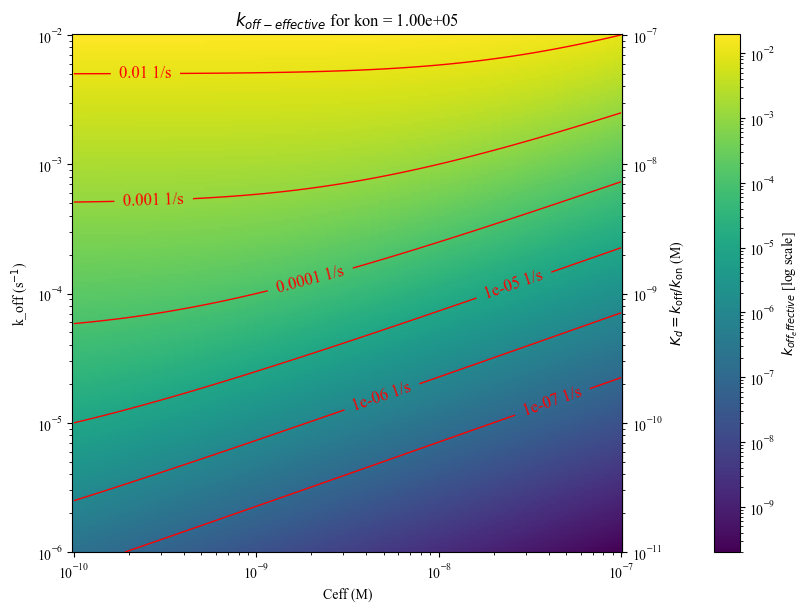

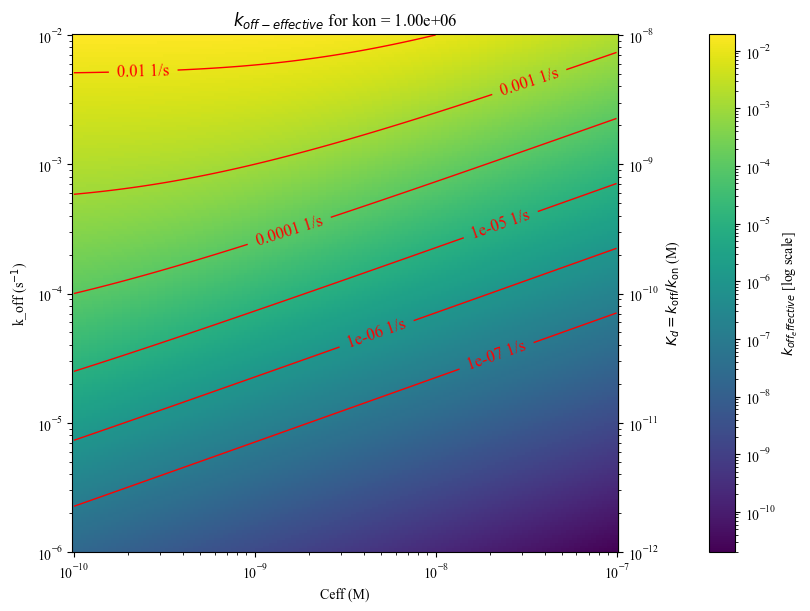

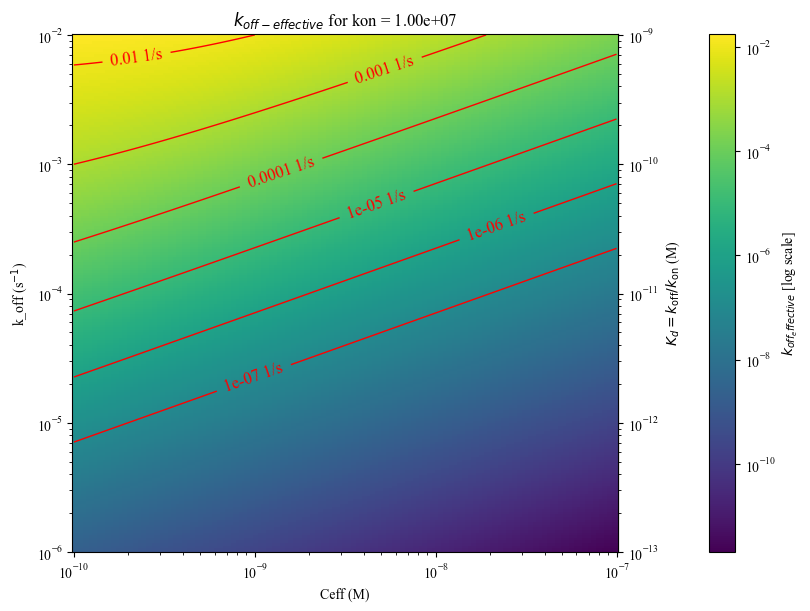

In [53]:
plot_koff_effective(1e5)
plot_koff_effective(1e6)
plot_koff_effective(1e7)

In [1]:
kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 1.74e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
C_eff = 200e-9 # M
model = "homodimer"
T=1e-12


keq_eff = calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)
kon_eff = calculate_kon_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)
koff_eff = calculate_koff_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)

print("kon_eff: ", kon_eff)
print("koff_eff: ", koff_eff)
print("keq_eff: ", keq_eff)

model = "simple"
keq_eff = calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)
kon_eff = calculate_kon_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)
koff_eff = calculate_koff_eff_full(kon=kon_1, koff=koff_1, C_eff=C_eff, T=1e-12, model=model)

print("kon_eff: ", kon_eff)
print("koff_eff: ", koff_eff)
print("keq_eff: ", keq_eff)

NameError: name 'calculate_k_eff_full' is not defined

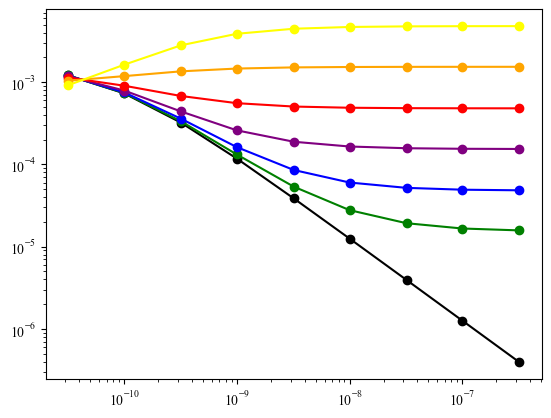

In [13]:
kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 0.5*1.74e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
model = "homodimer"
T=0e-12

Ceff_list = [32e-12, 100e-12, 320e-12,1e-9, 3.2e-9, 10e-9, 32e-9, 100e-9, 320e-9]

keff_list_0pM = []
keff_list_320fM = []
keff_list_1pM = []
keff_list_3_2pM = []
keff_list_10pM = []
keff_list_32pM = []
keff_list_100pM = []



for C in Ceff_list:
    keff_list_0pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=0e-12, model=model))
    keff_list_320fM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=320e-15, model=model))
    keff_list_1pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=1e-12, model=model))
    keff_list_3_2pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=3.2e-12, model=model))
    keff_list_10pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=10e-12, model=model))
    keff_list_32pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=32e-12, model=model))
    keff_list_100pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=100e-12, model=model))

plt.plot(Ceff_list, keff_list_0pM, marker='o', color="black", label="0 pM")
plt.plot(Ceff_list, keff_list_320fM, marker='o', color="green", label="320 fM")
plt.plot(Ceff_list, keff_list_1pM, marker='o', color="blue", label="1 pM")
plt.plot(Ceff_list, keff_list_3_2pM, marker='o', color="purple", label="1 pM")
plt.plot(Ceff_list, keff_list_10pM, marker='o', color="red", label="10 pM")
plt.plot(Ceff_list, keff_list_32pM, marker='o', color="orange", label="32 pM")
plt.plot(Ceff_list, keff_list_100pM, marker='o', color="yellow", label="100 pM")


plt.xscale("log")
plt.yscale("log")



In [ ]:
kon_1 = 1.2e7 #3.0e5 # 1/(M*s)
kon_2 = kon_1 #3.0e5 # 1/(M*s)
koff_1 = 0.5*1.74e-3 #1.5e-3 #1/s
koff_2 = koff_1 #1.5e-3 #1/s
model = "homodimer"
T=0e-12

Ceff_list = [32e-12, 100e-12, 320e-12,1e-9, 3.2e-9, 10e-9, 32e-9, 100e-9, 320e-9]

keff_list_0pM = []
keff_list_320fM = []
keff_list_1pM = []
keff_list_3_2pM = []
keff_list_10pM = []
keff_list_32pM = []
keff_list_100pM = []



for C in Ceff_list:
    keff_list_0pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=0e-12, model=model))
    keff_list_320fM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=320e-15, model=model))
    keff_list_1pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=1e-12, model=model))
    keff_list_3_2pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=3.2e-12, model=model))
    keff_list_10pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=10e-12, model=model))
    keff_list_32pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=32e-12, model=model))
    keff_list_100pM.append(calculate_k_eff_full(kon=kon_1, koff=koff_1, C_eff=C, T=100e-12, model=model))

plt.plot(Ceff_list, keff_list_0pM, marker='o', color="black", label="0 pM")
plt.plot(Ceff_list, keff_list_320fM, marker='o', color="green", label="320 fM")
plt.plot(Ceff_list, keff_list_1pM, marker='o', color="blue", label="1 pM")
plt.plot(Ceff_list, keff_list_3_2pM, marker='o', color="purple", label="1 pM")
plt.plot(Ceff_list, keff_list_10pM, marker='o', color="red", label="10 pM")
plt.plot(Ceff_list, keff_list_32pM, marker='o', color="orange", label="32 pM")
plt.plot(Ceff_list, keff_list_100pM, marker='o', color="yellow", label="100 pM")


plt.xscale("log")
plt.yscale("log")

